### Time series analysis on the data International Airline passengers from 1940 to 1960

In [28]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression

In [2]:
# Data fetch from github
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
df = pd.read_csv(url)
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [6]:
df.shape

(144, 2)

<Axes: xlabel='Month', ylabel='Passengers'>

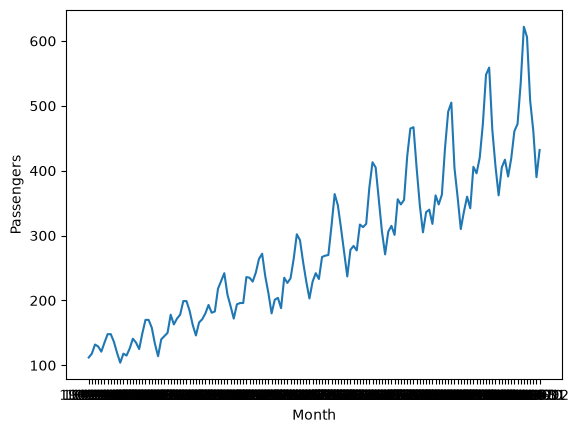

In [5]:
# plot the data to see trends and seasonality with seaborn
sns.lineplot(data=df, x='Month', y='Passengers')

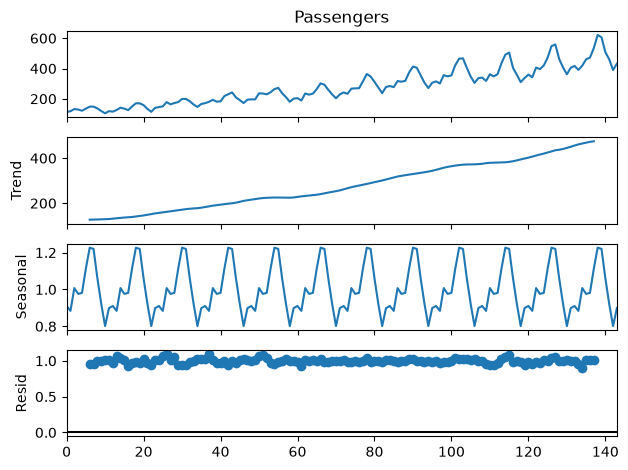

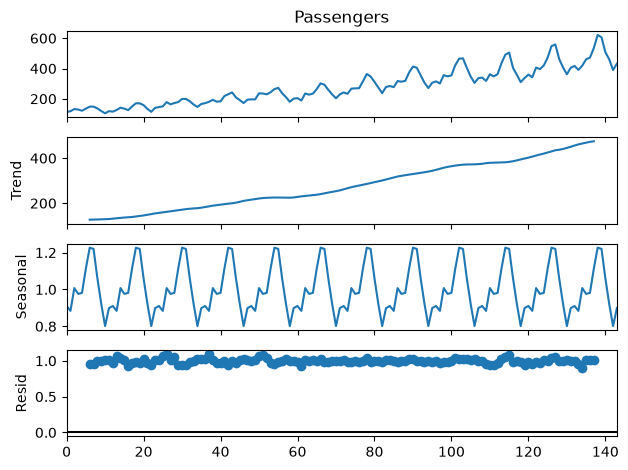

In [7]:
# decompose the time series data to see trend, seasonality and residuals
decompose = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)
decompose.plot()

<Axes: >

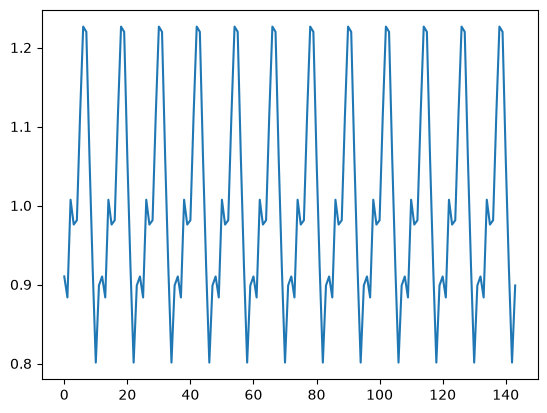

In [15]:
decompose.seasonal.plot()

<Axes: >

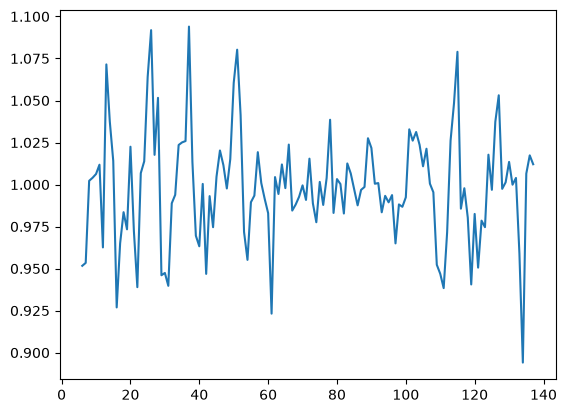

In [13]:
decompose.resid.plot()

<Axes: >

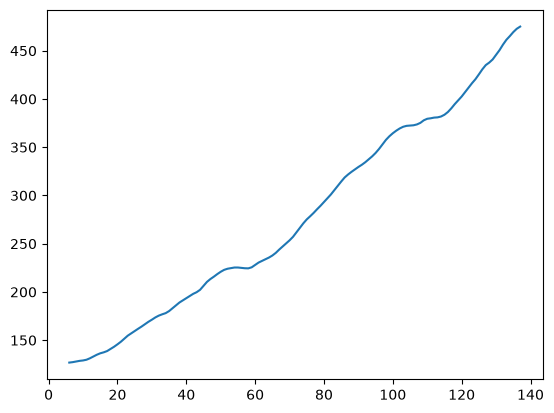

In [14]:
decompose.trend.plot()

In [16]:
trend = decompose.trend
seasonal = decompose.seasonal
residual = decompose.resid

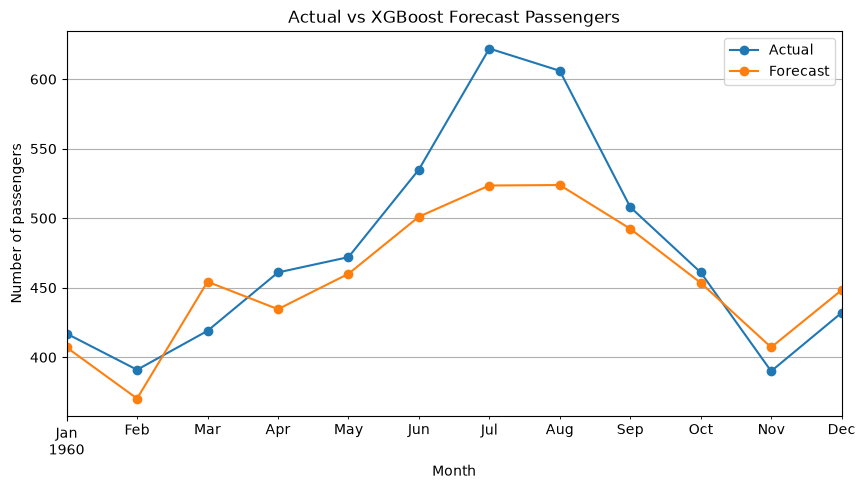

MAE:  31.29
RMSE: 41.91
MAPE: 6.08%


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Use the final 12 months as the test set
train = df.iloc[:-12].copy()
test = df.iloc[-12:].copy()

# Scale passenger values using training data only
passenger_scaler = MinMaxScaler()
scaled_train = passenger_scaler.fit_transform(
    train[['Passengers']].values
).flatten()

lookback = 24
X_train, y_train = [], []

for i in range(lookback, len(scaled_train)):
    month = train.index[i - lookback:i].month
    passenger_sequence = scaled_train[i - lookback:i]

    X_train.append(np.column_stack([
        passenger_sequence,
        np.sin(2 * np.pi * month / 12),
        np.cos(2 * np.pi * month / 12),
    ]))
    y_train.append(scaled_train[i])

X_train = np.asarray(X_train)
y_train = np.asarray(y_train)

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(lookback, 3)),
    LSTM(64, activation='tanh'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=30,
    restore_best_weights=True,
)

history = model.fit(
    X_train,
    y_train,
    epochs=500,
    batch_size=16,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=0,
)

# Recursive multi-step forecast
passenger_history = list(scaled_train)
predictions_scaled = []

for date in test.index:
    start = len(passenger_history) - lookback
    history_window = passenger_history[start:]

    feature_sequence = np.column_stack([
        history_window,
        np.sin(
            2 * np.pi
            * pd.date_range(
                periods=lookback,
                freq='MS',
                end=date
            ).month
            / 12
        ),
        np.cos(
            2 * np.pi
            * pd.date_range(
                periods=lookback,
                freq='MS',
                end=date
            ).month
            / 12
        ),
    ])

    next_prediction = model.predict(
        feature_sequence[np.newaxis, :, :],
        verbose=0,
    )[0, 0]

    predictions_scaled.append(next_prediction)
    passenger_history.append(next_prediction)

predictions = passenger_scaler.inverse_transform(
    np.asarray(predictions_scaled).reshape(-1, 1)
).flatten()

forecast = pd.Series(predictions, index=test.index, name='Forecast')

comparison = pd.DataFrame({
    'Actual': test['Passengers'],
    'Forecast': forecast,
})

comparison.plot(figsize=(10, 5), marker='o')
plt.title('Actual vs RNN Forecast Passengers')
plt.ylabel('Number of passengers')
plt.grid(True)
plt.show()

errors = comparison['Actual'] - comparison['Forecast']
mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
mape = np.mean(np.abs(errors / comparison['Actual'])) * 100

print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAPE: {mape:.2f}%')